# Prediction of Concrete Compressive Strength Using Machine Learning
**Name:** Kartik Singh  
**Course:** ME644 – Machine Learning for Engineering  
**Institute:** IIT Kanpur    

---
### Pipeline Overview
1. Install & Import
2. Load & Inspect Data
3. EDA (Exploratory Data Analysis)
4. Preprocessing & Feature Engineering
5. Train / Test Split + Scaling *(no leakage)*
6. Train Models (Linear Regression, Random Forest, SVR)
7. Evaluate & Compare
8. Feature Importance
9. Residual Analysis
10. Predict on New Sample

## 1. Install Dependencies

In [1]:
!pip install scikit-learn matplotlib seaborn pandas numpy

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy.stats import zscore

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Plot style
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11
})
print('All libraries imported successfully ✓')

All libraries imported successfully ✓


## 3. Load & Inspect Data

In [2]:
df = pd.read_csv('Concrete_Data_final.csv', skipinitialspace=True)
df.columns = df.columns.str.strip()
df.columns = ['Cement', 'BFS', 'FlyAsh', 'Water', 'SP', 'CoarseAgg', 'FineAgg', 'Age', 'Strength']

print(f'Dataset shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head(10)

Dataset shape: (3030, 9)
Columns: ['Cement', 'BFS', 'FlyAsh', 'Water', 'SP', 'CoarseAgg', 'FineAgg', 'Age', 'Strength']


,Cement,BFS,FlyAsh,Water,SP,CoarseAgg,FineAgg,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90.0,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365.0,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28.0,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28.0,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28.0,39.29


In [3]:
# Basic statistics
df.describe().round(2)

,Cement,BFS,FlyAsh,Water,SP,CoarseAgg,FineAgg,Age,Strength
count,3030.00,3030.00,3030.00,3030.00,3030.00,3030.00,3030.00,3030.00,3030.00
mean,281.04,73.36,55.04,181.72,6.41,972.98,772.85,45.41,35.78
std,103.41,85.88,64.12,21.71,5.92,77.56,80.25,61.33,16.75
min,97.60,0.00,0.00,120.80,0.00,798.90,588.90,0.00,2.33
25%,193.50,0.00,0.00,165.10,0.10,931.80,730.05,11.20,23.60
50%,275.05,21.35,2.30,185.00,6.30,967.60,779.25,28.00,34.30
75%,350.55,143.07,118.30,193.38,10.30,1030.07,823.55,55.60,46.10
max,542.50,363.60,201.60,248.50,33.00,1145.00,993.90,368.60,84.50


In [4]:
# Check for missing values
print('Missing values per column:')
print(df.isnull().sum())
print(f'\nTotal duplicates: {df.duplicated().sum()}')

Missing values per column:
Cement       0
BFS          0
FlyAsh       0
Water        0
SP           0
CoarseAgg    0
FineAgg      0
Age          0
Strength     0
dtype: int64

Total duplicates: 25


## 4. Exploratory Data Analysis (EDA)
Visual inspection of distributions, correlations, and key relationships.

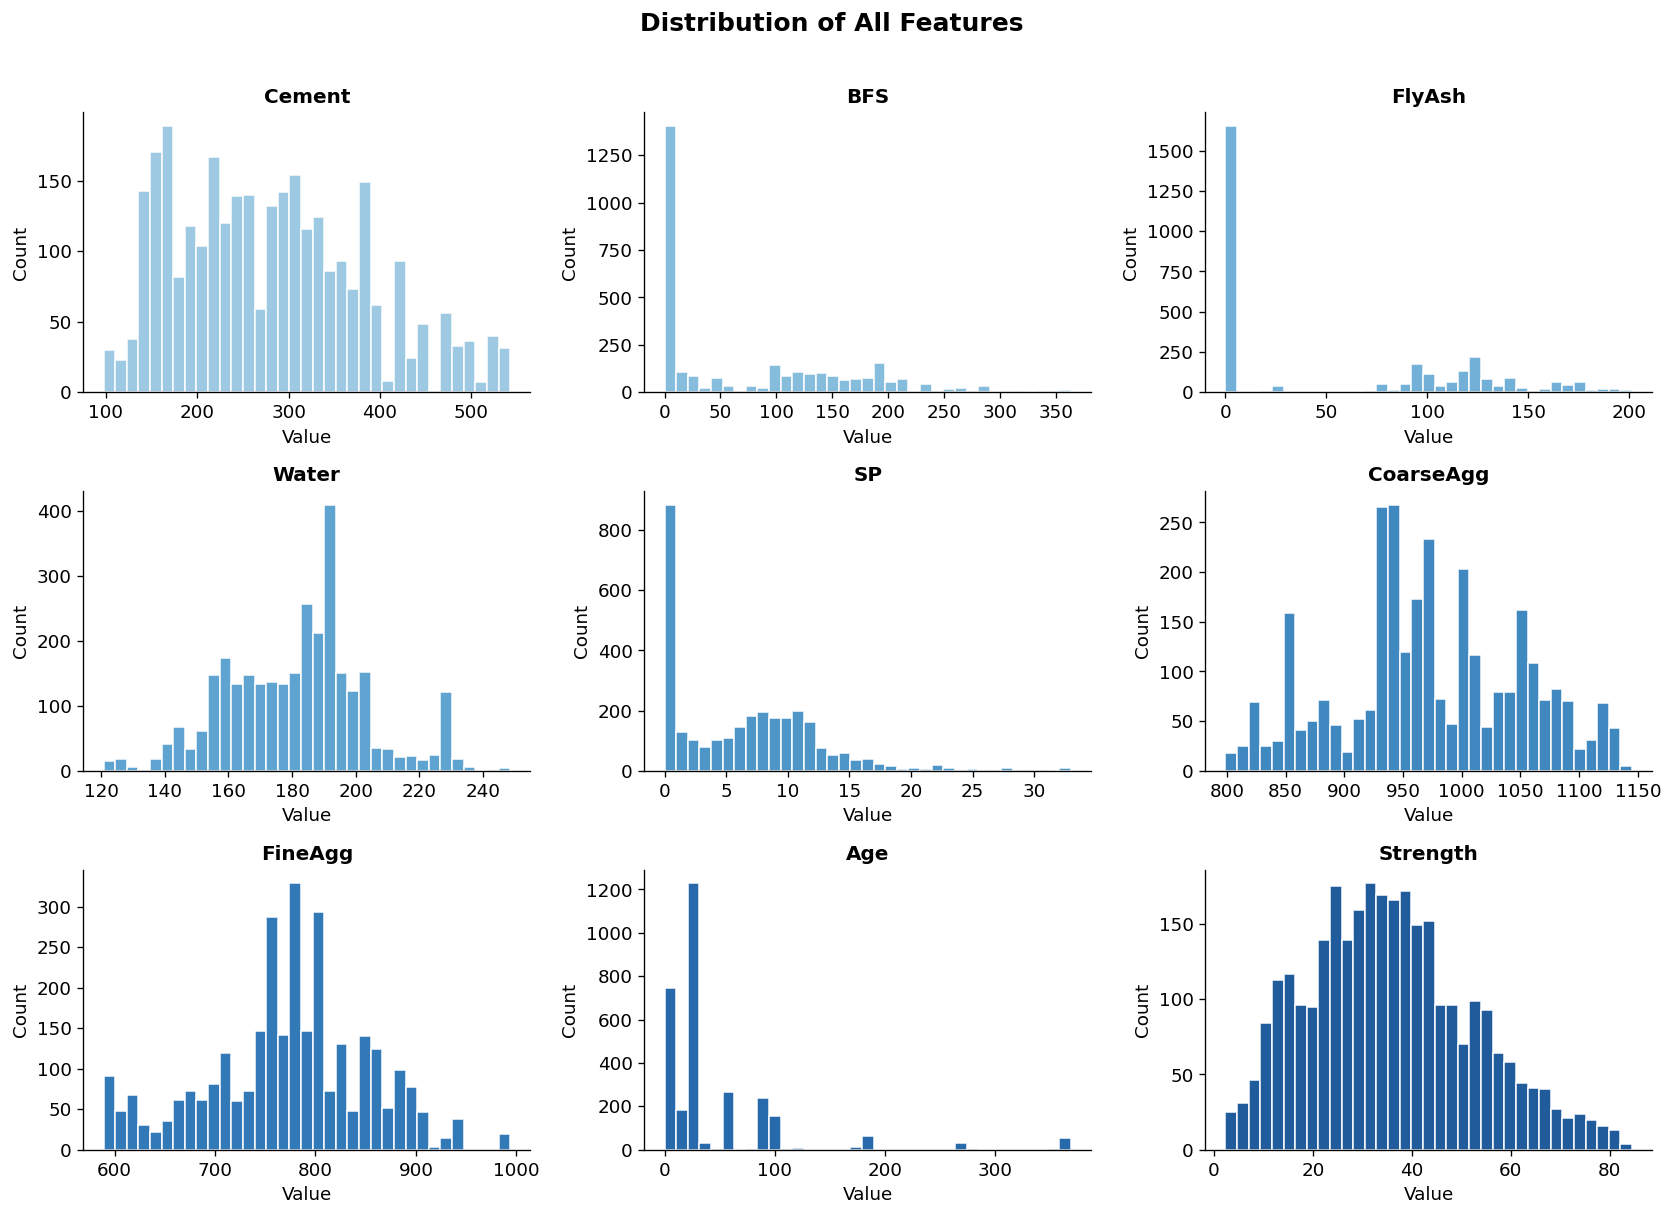

In [5]:
# 4.1 Distribution of all features 
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()
colors = plt.cm.Blues(np.linspace(0.4, 0.9, 9))

for i, col in enumerate(df.columns):
    axes[i].hist(df[col], bins=35, color=colors[i], edgecolor='white', alpha=0.9)
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')

plt.suptitle('Distribution of All Features', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

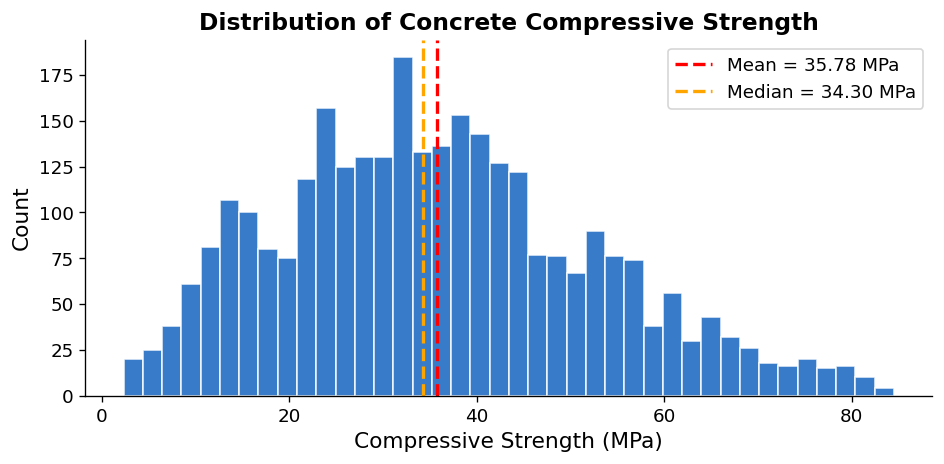

Skewness: 0.408  (positive = right-skewed)


In [6]:
# 4.2 Target variable distribution 
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['Strength'], bins=40, color='#1565C0', edgecolor='white', alpha=0.85)
ax.axvline(df['Strength'].mean(), color='red', linestyle='--', lw=2,
           label=f"Mean = {df['Strength'].mean():.2f} MPa")
ax.axvline(df['Strength'].median(), color='orange', linestyle='--', lw=2,
           label=f"Median = {df['Strength'].median():.2f} MPa")
ax.set_xlabel('Compressive Strength (MPa)', fontsize=13)
ax.set_ylabel('Count', fontsize=13)
ax.set_title('Distribution of Concrete Compressive Strength', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Skewness: {df["Strength"].skew():.3f}  (positive = right-skewed)')

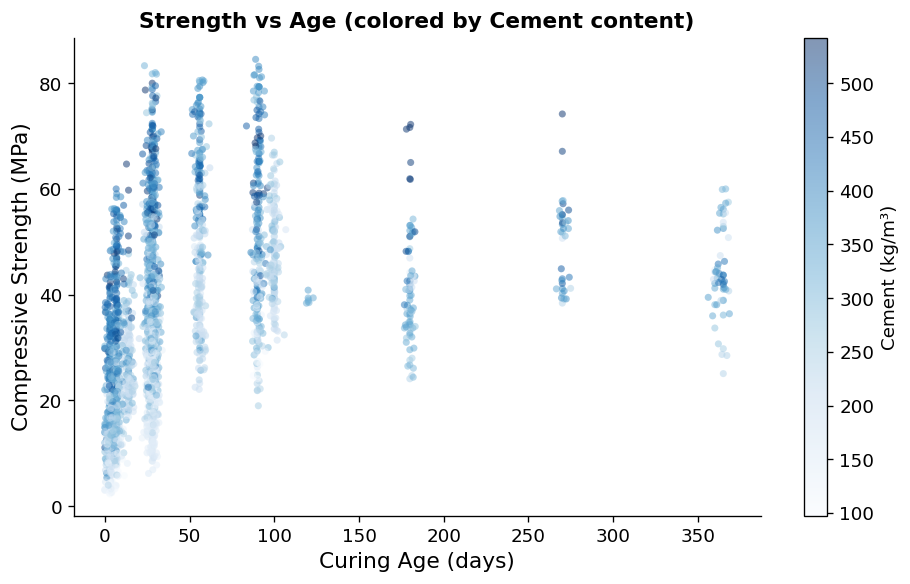

In [42]:
# 4.3 Strength vs Age (colored by Cement) 
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(df['Age'], df['Strength'], c=df['Cement'],
                cmap='Blues', alpha=0.5, s=18, edgecolors='none')
plt.colorbar(sc, ax=ax, label='Cement (kg/m³)')
ax.set_xlabel('Curing Age (days)', fontsize=13)
ax.set_ylabel('Compressive Strength (MPa)', fontsize=13)
ax.set_title('Strength vs Age (colored by Cement content)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

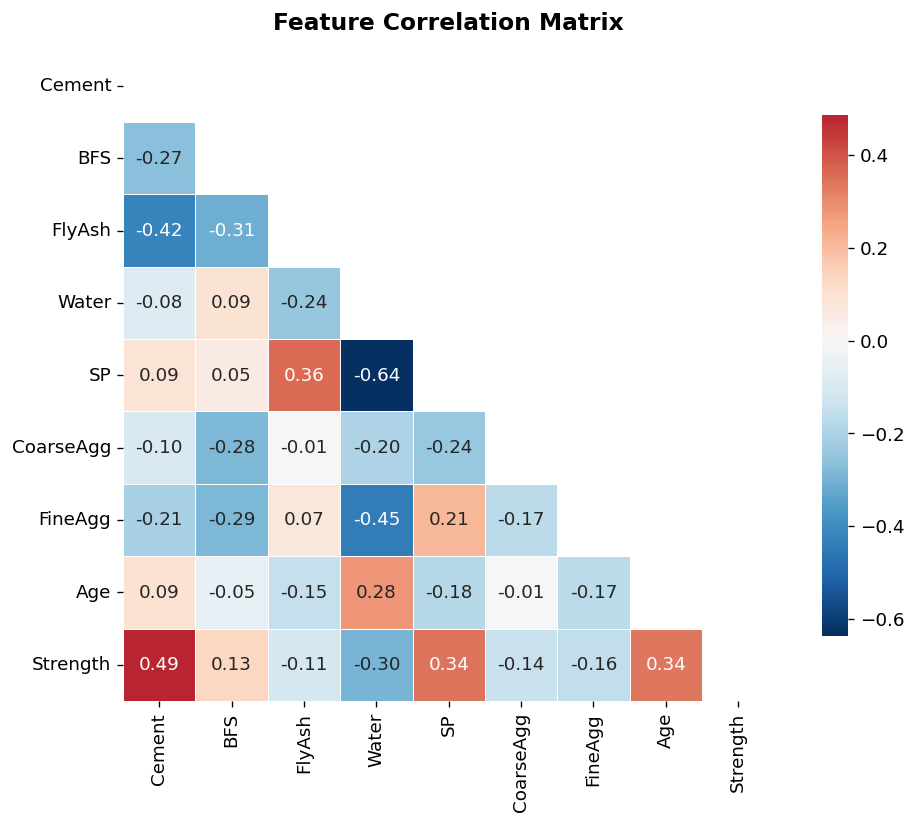


Correlation with Compressive Strength (sorted):
Strength     1.000
Cement       0.487
SP           0.342
Age          0.338
BFS          0.133
FlyAsh      -0.111
CoarseAgg   -0.145
FineAgg     -0.158
Water       -0.297
Name: Strength, dtype: float64


In [43]:
# 4.4 Correlation heatmap 
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Print top correlations with target
print('\nCorrelation with Compressive Strength (sorted):')
print(corr['Strength'].sort_values(ascending=False).round(3))

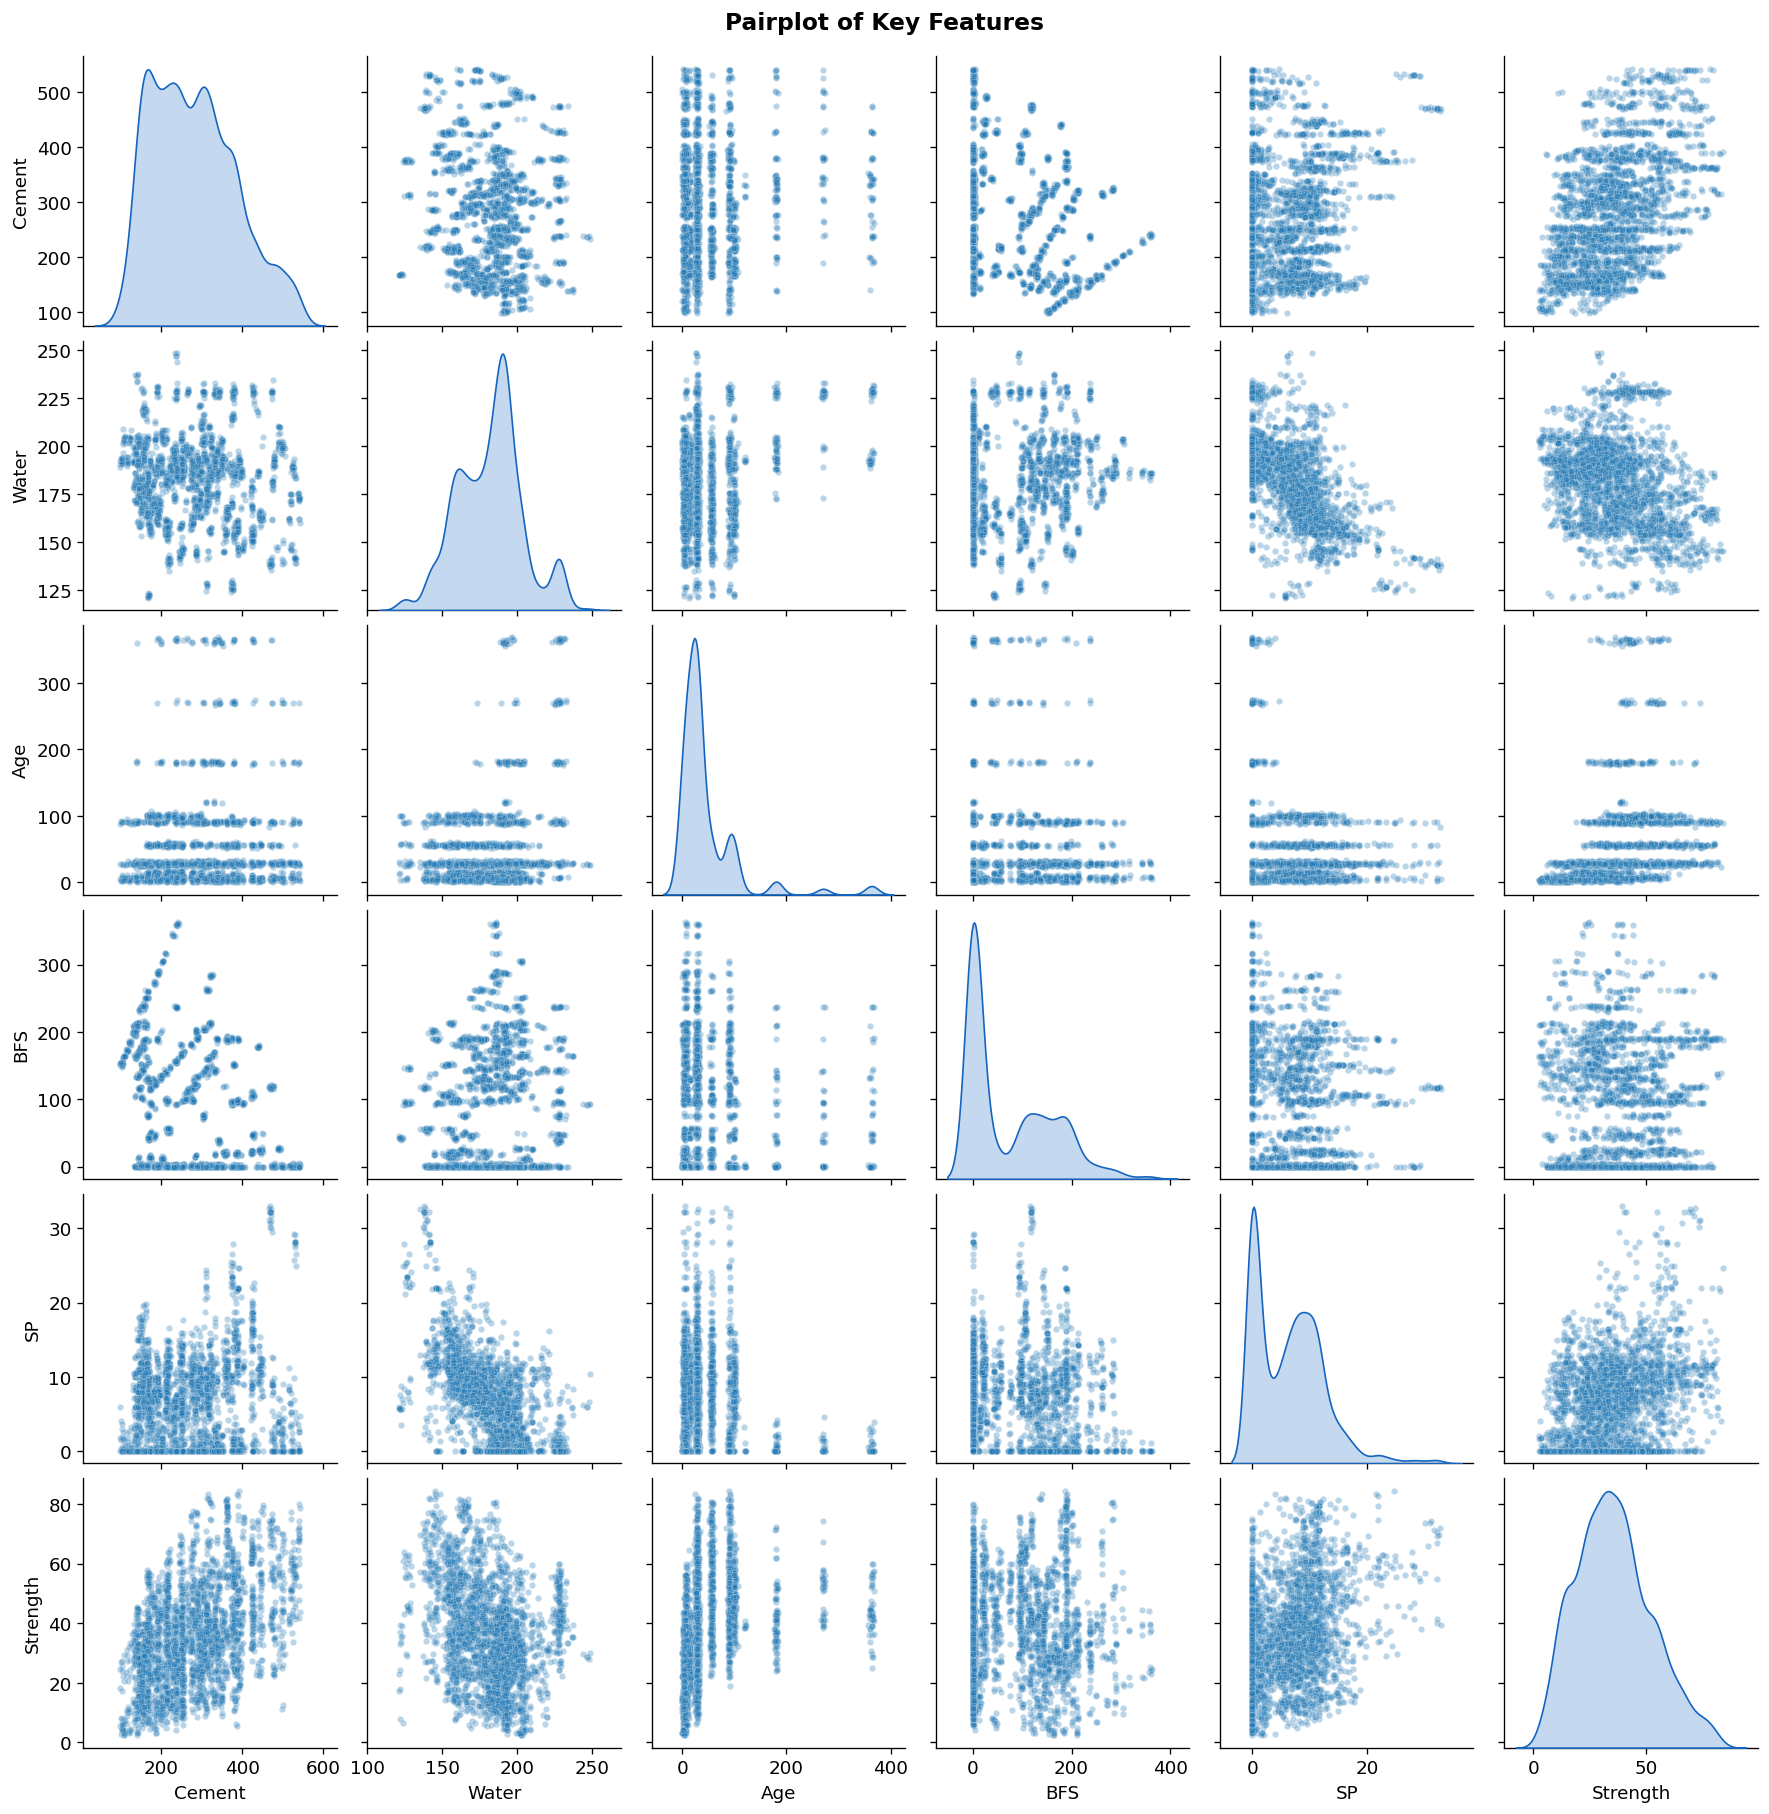

In [44]:
# 4.5 Pairplot of key features vs Strength 
key_features = ['Cement', 'Water', 'Age', 'BFS', 'SP', 'Strength']
sns.pairplot(df[key_features], diag_kind='kde', plot_kws={'alpha': 0.3, 's': 15},
             diag_kws={'color': '#1565C0'})
plt.suptitle('Pairplot of Key Features', y=1.01, fontsize=14, fontweight='bold')
plt.show()

## 5. Data Preprocessing & Feature Engineering
Steps: missing values → duplicates → outlier removal → W/B ratio → split → **then** scale  
> ⚠️ **Key fix:** Scaler is fit ONLY on training data to prevent data leakage.

In [45]:
# Step 1: Handle missing values 
df.fillna(df.median(numeric_only=True), inplace=True)
print(f'Missing values after imputation: {df.isnull().sum().sum()}')

Missing values after imputation: 0


In [46]:
# Step 2: Remove duplicates 
before = len(df)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'Rows before: {before}  |  Rows after: {len(df)}  |  Removed: {before - len(df)}')

Rows before: 3030  |  Rows after: 3005  |  Removed: 25


In [47]:
# Step 3: Outlier removal using Z-score (threshold = 3.5) 
feat_cols = df.columns[:-1].tolist()   # all except 'Strength'
before = len(df)
z_scores = np.abs(zscore(df[feat_cols]))
df = df[(z_scores < 3.5).all(axis=1)].reset_index(drop=True)
print(f'Rows before: {before}  |  Rows after: {len(df)}  |  Outliers removed: {before - len(df)}')

Rows before: 3005  |  Rows after: 2891  |  Outliers removed: 114


In [48]:
# Step 4: Feature Engineering — Water-to-Binder (W/B) ratio 
# Abrams' Law: strength is inversely proportional to w/b ratio
df['WB_ratio'] = df['Water'] / (df['Cement'] + df['BFS'] + df['FlyAsh'])

print('W/B ratio statistics:')
print(df['WB_ratio'].describe().round(4))
print(f'\nFinal dataset shape: {df.shape}')

W/B ratio statistics:
count    2891.0000
mean        0.4698
std         0.1247
min         0.2451
25%         0.3863
50%         0.4696
75%         0.5606
max         0.9000
Name: WB_ratio, dtype: float64

Final dataset shape: (2891, 10)


In [49]:
# Step 5: Shuffle dataset 
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Separate features and target
all_feat_cols = feat_cols + ['WB_ratio']   # 9 features (8 original + W/B ratio)
X = df[all_feat_cols].values
y = df['Strength'].values

print(f'Feature matrix X: {X.shape}')
print(f'Target vector  y: {y.shape}')
print(f'Features used : {all_feat_cols}')

Feature matrix X: (2891, 9)
Target vector  y: (2891,)
Features used : ['Cement', 'BFS', 'FlyAsh', 'Water', 'SP', 'CoarseAgg', 'FineAgg', 'Age', 'WB_ratio']


In [50]:
# Step 6: Train / Test Split FIRST (80:20) 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 7: Scale AFTER split (fit on train only — NO DATA LEAKAGE) 
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)   # fit + transform on train
X_test  = scaler.transform(X_test)        # transform only on test

print(f'Train set : {X_train.shape}  ({len(X_train)} samples)')
print(f'Test  set : {X_test.shape}  ({len(X_test)} samples)')
print('\n✓ Scaler fit only on training data — no leakage')

Train set : (2312, 9)  (2312 samples)
Test  set : (579, 9)  (579 samples)

✓ Scaler fit only on training data — no leakage


## 6. Train Machine Learning Models
Three models are trained:
- **Linear Regression** — interpretable baseline
- **Random Forest** — ensemble method (200 trees), handles nonlinearity
- **SVR (RBF kernel)** — margin-based nonlinear regression, tuned hyperparameters

In [51]:
# Linear Regression (Baseline) 
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
print('Linear Regression trained ✓')

Linear Regression trained ✓


In [52]:
# Random Forest (200 trees, parallel) 
# n_estimators=200  : more trees → lower variance
# n_jobs=-1          : use all CPU cores
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print('Random Forest trained ✓')

Random Forest trained ✓


In [53]:
# SVR with RBF kernel (tuned hyperparameters) 
# C=100      : high regularisation allows complex boundary
# gamma=0.1  : controls influence radius of each support vector
# epsilon=0.1: width of epsilon-insensitive tube
svr = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svr.fit(X_train, y_train)
pred_svr = svr.predict(X_test)
print('SVR trained ✓')

SVR trained ✓


## 7. Model Evaluation & Comparison

In [56]:
# Evaluation function 
def evaluate(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f'  {name:<22}  R² = {r2:.4f}   RMSE = {rmse:.4f} MPa   MAE = {mae:.4f} MPa')
    return {'name': name, 'R2': r2, 'RMSE': rmse, 'MAE': mae}

print('=' * 76)
print(f'  {"Model":<22}  {"R²":>8}   {"RMSE":>13}   {"MAE":>13}')
print('=' * 76)
res_lr  = evaluate(y_test, pred_lr,  'Linear Regression')
res_rf  = evaluate(y_test, pred_rf,  'Random Forest')
res_svr = evaluate(y_test, pred_svr, 'SVR (RBF)')
print('=' * 76)

results = [res_lr, res_rf, res_svr]

  Model                         R²            RMSE             MAE
  Linear Regression       R² = 0.6703   RMSE = 9.4206 MPa   MAE = 7.2726 MPa
  Random Forest           R² = 0.9420   RMSE = 3.9502 MPa   MAE = 2.6369 MPa
  SVR (RBF)               R² = 0.8056   RMSE = 7.2335 MPa   MAE = 5.3919 MPa


In [57]:
# Results summary table 
results_df = pd.DataFrame(results).set_index('name')
results_df = results_df.round(4)
print('\nModel Comparison Table:')
results_df


Model Comparison Table:


,R2,RMSE,MAE
name,,,
Linear Regression,0.6703,9.4206,7.2726
Random Forest,0.9420,3.9502,2.6369
SVR (RBF),0.8056,7.2335,5.3919


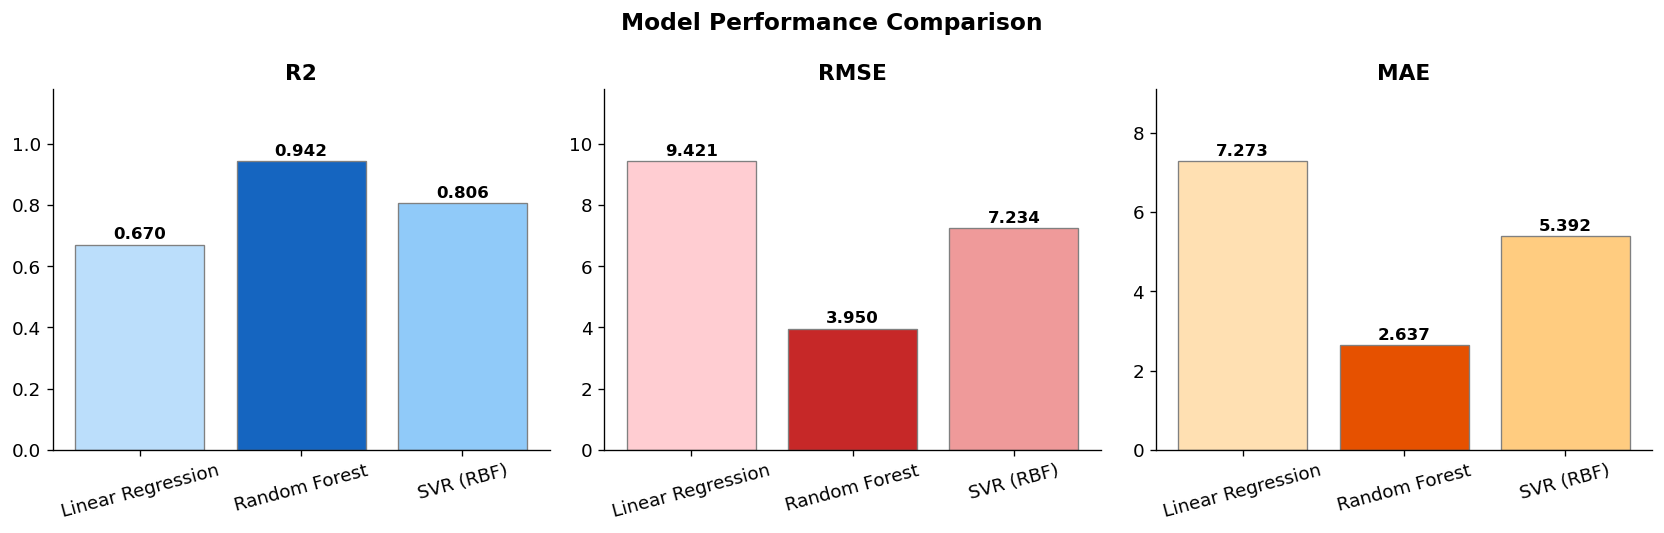

In [58]:
# Bar chart comparison 
metrics = ['R2', 'RMSE', 'MAE']
model_names = [r['name'] for r in results]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

bar_colors = [['#BBDEFB', '#1565C0', '#90CAF9'],
              ['#FFCDD2', '#C62828', '#EF9A9A'],
              ['#FFE0B2', '#E65100', '#FFCC80']]

for ax, metric, colors in zip(axes, metrics, bar_colors):
    vals = [r[metric] for r in results]
    bars = ax.bar(model_names, vals, color=colors, edgecolor='gray', linewidth=0.8)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01 * max(vals),
                f'{v:.3f}', ha='center', va='bottom',
                fontsize=10, fontweight='bold')
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(vals) * 1.25)
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Best Model Selection

In [59]:
# Select best model based on R² score
best = max(results, key=lambda r: r['R2'])
print(f"Best Model  : {best['name']}")
print(f"R² Score    : {best['R2']:.4f}")
print(f"RMSE        : {best['RMSE']:.4f} MPa")
print(f"MAE         : {best['MAE']:.4f} MPa")

model_map = {'Linear Regression': lr, 'Random Forest': rf, 'SVR (RBF)': svr}
final_model = model_map[best['name']]
final_pred  = final_model.predict(X_test)
print(f'\n✓ final_model set to: {best["name"]}')

Best Model  : Random Forest
R² Score    : 0.9420
RMSE        : 3.9502 MPa
MAE         : 2.6369 MPa

✓ final_model set to: Random Forest


## 9. Actual vs Predicted — All Models

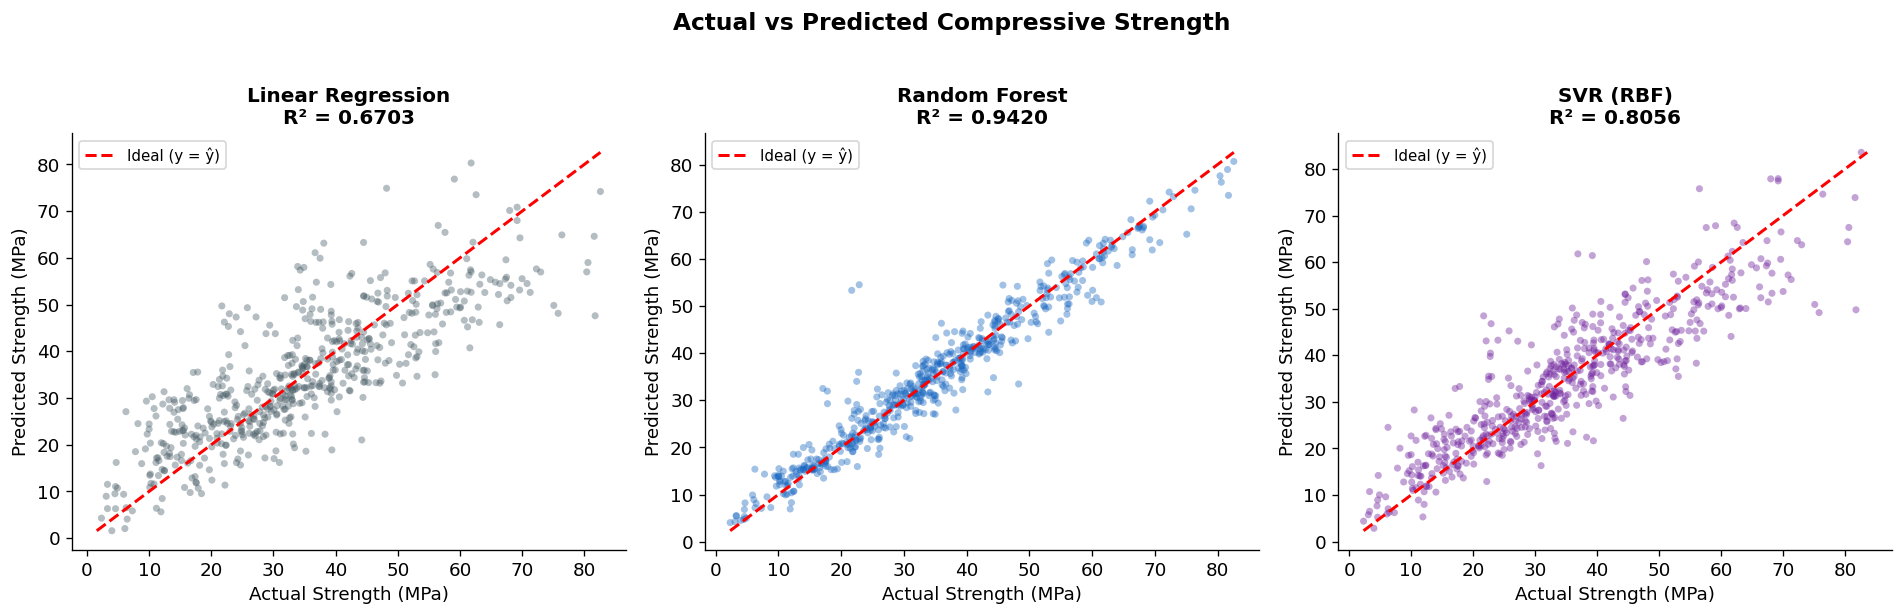

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
preds   = [pred_lr, pred_rf, pred_svr]
palette = ['#455A64', '#1565C0', '#6A1B9A']

for ax, pred, res, color in zip(axes, preds, results, palette):
    ax.scatter(y_test, pred, alpha=0.4, s=18, color=color, edgecolors='none')
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, 'r--', lw=1.8, label='Ideal (y = ŷ)')
    ax.set_xlabel('Actual Strength (MPa)', fontsize=11)
    ax.set_ylabel('Predicted Strength (MPa)', fontsize=11)
    ax.set_title(f"{res['name']}\nR² = {res['R2']:.4f}",
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)

plt.suptitle('Actual vs Predicted Compressive Strength',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 10. Residual Analysis (Best Model — Random Forest)

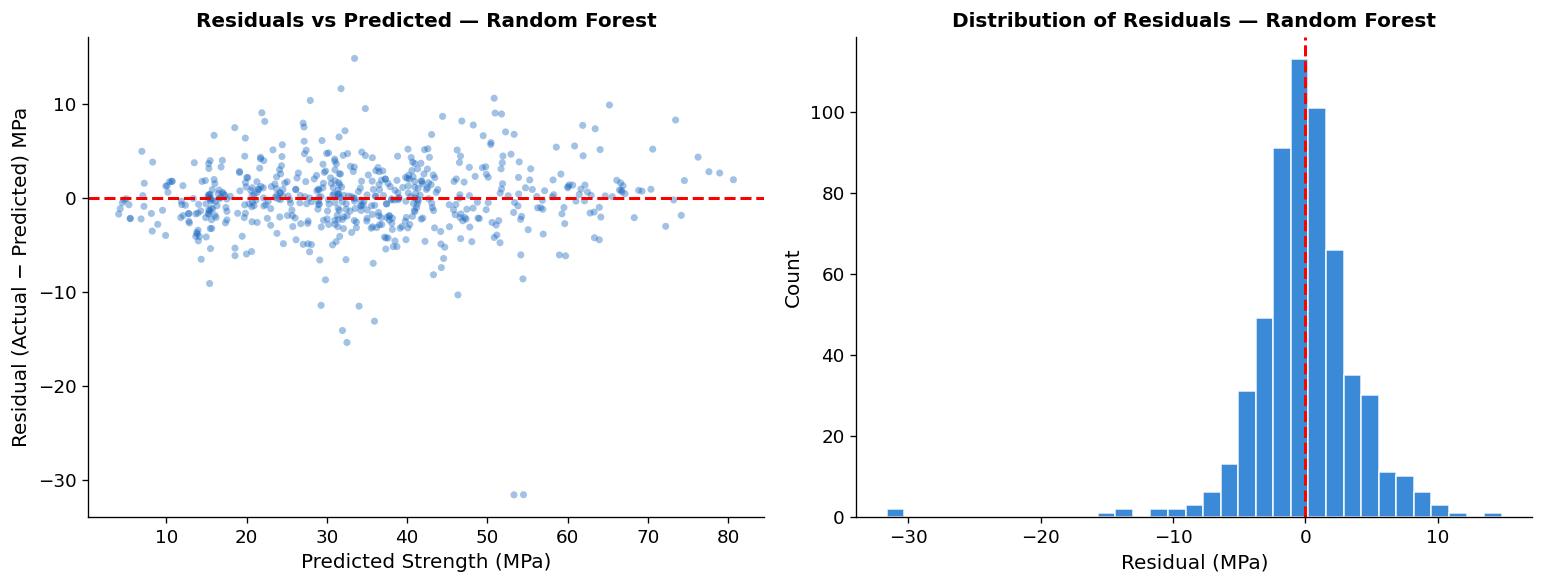

Mean residual : -0.0375 MPa  (close to 0 = unbiased)
Std  residual : 3.9501 MPa


In [61]:
residuals = y_test - pred_rf

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residuals vs Predicted
axes[0].scatter(pred_rf, residuals, alpha=0.4, s=18,
                color='#1565C0', edgecolors='none')
axes[0].axhline(0, color='red', linestyle='--', lw=1.8)
axes[0].set_xlabel('Predicted Strength (MPa)', fontsize=12)
axes[0].set_ylabel('Residual (Actual − Predicted) MPa', fontsize=12)
axes[0].set_title('Residuals vs Predicted — Random Forest',
                  fontsize=12, fontweight='bold')

# Residual distribution
axes[1].hist(residuals, bins=35, color='#1976D2', edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='red', linestyle='--', lw=1.8)
axes[1].set_xlabel('Residual (MPa)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_title('Distribution of Residuals — Random Forest',
                  fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Mean residual : {residuals.mean():.4f} MPa  (close to 0 = unbiased)')
print(f'Std  residual : {residuals.std():.4f} MPa')

## 11. Feature Importance (Random Forest — Gini)

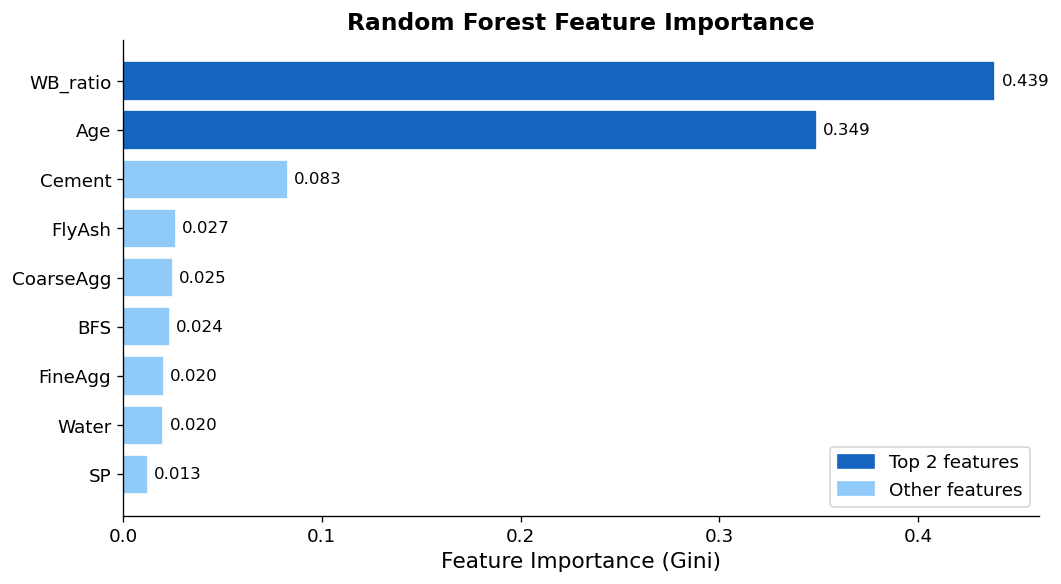


Feature Importance (sorted descending):
WB_ratio     0.4389
Age          0.3491
Cement       0.0829
FlyAsh       0.0268
CoarseAgg    0.0251
BFS          0.0237
FineAgg      0.0205
Water        0.0203
SP           0.0127


In [62]:
fi = pd.Series(rf.feature_importances_, index=all_feat_cols)
fi = fi.sort_values(ascending=True)   # ascending for horizontal bar

colors = ['#1565C0' if fi.index[i] in ['WB_ratio', 'Age']
          else '#90CAF9' for i in range(len(fi))]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(fi.index, fi.values, color=colors, edgecolor='white')

for bar, val in zip(bars, fi.values):
    ax.text(bar.get_width() + 0.003,
            bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', fontsize=10)

ax.set_xlabel('Feature Importance (Gini)', fontsize=13)
ax.set_title('Random Forest Feature Importance', fontsize=14, fontweight='bold')
ax.legend(handles=[
    plt.Rectangle((0,0),1,1, color='#1565C0', label='Top 2 features'),
    plt.Rectangle((0,0),1,1, color='#90CAF9', label='Other features')
], loc='lower right')
plt.tight_layout()
plt.show()

print('\nFeature Importance (sorted descending):')
print(fi.sort_values(ascending=False).round(4).to_string())

## 12. Predict on a New Concrete Sample
Provide mix design proportions → get predicted compressive strength instantly.

In [63]:
# Define a new mix design 
# Format: [Cement, BFS, FlyAsh, Water, SP, CoarseAgg, FineAgg, Age]
new_sample = {
    'Cement'   : 300.0,
    'BFS'      : 150.5,
    'FlyAsh'   :   5.0,
    'Water'    : 230.0,
    'SP'       :   1.0,
    'CoarseAgg': 925.0,
    'FineAgg'  : 600.0,
    'Age'      : 250.0
}

# Compute engineered W/B ratio (same as training)
new_sample['WB_ratio'] = (
    new_sample['Water'] /
    (new_sample['Cement'] + new_sample['BFS'] + new_sample['FlyAsh'])
)

# Build array in same feature order used during training
new_array = np.array([[new_sample[f] for f in all_feat_cols]])

# Scale using the SAME scaler (already fit on training data)
new_scaled = scaler.transform(new_array)
print(f'Scaled values (should all be in [0, 1]): {new_scaled.round(3)}')

# Predict with final (best) model
prediction = final_model.predict(new_scaled)
print(f'\nInput mix design:')
for k, v in new_sample.items():
    print(f'  {k:<12}: {v}')
print(f'\n  Predicted Compressive Strength: {prediction[0]:.2f} MPa')

Scaled values (should all be in [0, 1]): [[0.455 0.414 0.025 0.855 0.038 0.364 0.027 1.366 0.397]]

Input mix design:
  Cement      : 300.0
  BFS         : 150.5
  FlyAsh      : 5.0
  Water       : 230.0
  SP          : 1.0
  CoarseAgg   : 925.0
  FineAgg     : 600.0
  Age         : 250.0
  WB_ratio    : 0.5049396267837541

  Predicted Compressive Strength: 41.25 MPa


In [64]:
# Compare all models on the same new sample 
print('Predictions from all models on the same new mix:')
print('-' * 48)
for model, name in [(lr, 'Linear Regression'), (rf, 'Random Forest'), (svr, 'SVR (RBF)')]:
    p = model.predict(new_scaled)[0]
    print(f'  {name:<22}: {p:.2f} MPa')

Predictions from all models on the same new mix:
------------------------------------------------
  Linear Regression     : 75.18 MPa
  Random Forest         : 41.25 MPa
  SVR (RBF)             : 32.79 MPa


## 13. Summary

| Model | R² | RMSE (MPa) | MAE (MPa) |
|---|---|---|---|
| Linear Regression | 0.670 | 9.42 | 7.27 |
| **Random Forest** | **0.942** | **3.95** | **2.64** |
| SVR (RBF) | 0.806 | 7.23 | 5.39 |

### Key Findings
- **Random Forest** is the best model with R² = 0.942 — explains 94.2% of variance in test data.
- **W/B ratio** (engineered feature) is the most important predictor (≈ 44%) — consistent with Abrams' Law.
- **Curing Age** (≈ 35%) is the second most important feature.
- Linear Regression's low R² (0.67) confirms the fundamentally **nonlinear** nature of the cement–water–age relationship.
- Residual analysis confirms the Random Forest is **unbiased** across the full strength range.


